<a href="https://colab.research.google.com/github/harigovindankjhari-afk/AI-DATASCIENCE_ASSIGNMENTS/blob/main/ML_DataPreprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("hello")

hello


In [ ]:
#Data prepropcessing (handling missingvalues)
import numpy as np
import pandas as pd

data = {
    'Age':[25,np.nan,30,np.nan,35],
    'Salary':[50000,60000,np.nan,80000,np.nan],
    'Dept':['HR',np.nan,'IT','HR',np.nan]
}
df=pd.DataFrame(data)
print(df)
df

    Age   Salary Dept
0  25.0  50000.0   HR
1   NaN  60000.0  NaN
2  30.0      NaN   IT
3   NaN  80000.0   HR
4  35.0      NaN  NaN


,Age,Salary,Dept
0,25.0,50000.0,HR
1,NaN,60000.0,NaN
2,30.0,NaN,IT
3,NaN,80000.0,HR
4,35.0,NaN,NaN


In [ ]:
df['Age']=df['Age'].fillna(df['Age'].mean())
print(df)
df

    Age   Salary Dept
0  25.0  50000.0   HR
1  30.0  60000.0  NaN
2  30.0      NaN   IT
3  30.0  80000.0   HR
4  35.0      NaN  NaN


,Age,Salary,Dept
0,25.0,50000.0,HR
1,30.0,60000.0,NaN
2,30.0,NaN,IT
3,30.0,80000.0,HR
4,35.0,NaN,NaN


In [ ]:
df['Salary']=df['Salary'].fillna(df['Salary'].median())
print(df)
df

    Age   Salary Dept
0  25.0  50000.0   HR
1  30.0  60000.0  NaN
2  30.0  60000.0   IT
3  30.0  80000.0   HR
4  35.0  60000.0  NaN


,Age,Salary,Dept
0,25.0,50000.0,HR
1,30.0,60000.0,NaN
2,30.0,60000.0,IT
3,30.0,80000.0,HR
4,35.0,60000.0,NaN


In [ ]:
df['Dept']=df['Dept'].fillna(df['Dept'].mode()[0])
print(df)
df

    Age   Salary Dept
0  25.0  50000.0   HR
1  30.0  60000.0   HR
2  30.0  60000.0   IT
3  30.0  80000.0   HR
4  35.0  60000.0   HR


,Age,Salary,Dept
0,25.0,50000.0,HR
1,30.0,60000.0,HR
2,30.0,60000.0,IT
3,30.0,80000.0,HR
4,35.0,60000.0,HR


In [ ]:
#HANDLING DUPLICATES
import pandas as pd
data = {
    'name':['Alice','Bob','Alice','Charlie','Bob'],
    'Score':[85,90,85,78,90]
}
df=pd.DataFrame(data)
print(df)
df

      name  Score
0    Alice     85
1      Bob     90
2    Alice     85
3  Charlie     78
4      Bob     90


,name,Score
0,Alice,85
1,Bob,90
2,Alice,85
3,Charlie,78
4,Bob,90


In [ ]:
print(df.duplicated())
df

0    False
1    False
2     True
3    False
4     True
dtype: bool


,name,Score
0,Alice,85
1,Bob,90
2,Alice,85
3,Charlie,78
4,Bob,90


In [ ]:
print(df.duplicated().sum())

2


In [ ]:
df_clean=df.drop_duplicates(subset=["name"])
print(df_clean)

      name  Score
0    Alice     85
1      Bob     90
3  Charlie     78


In [ ]:
df_clean=df.drop_duplicates()
print(df_clean)

      name  Score
0    Alice     85
1      Bob     90
3  Charlie     78


In [ ]:
#handling outliers,1)boxplot
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
data=[10,12,13,12,14,150,11,13,9,200,15]
df=pd.DataFrame({'Value':data})
print(df)




    Value
0      10
1      12
2      13
3      12
4      14
5     150
6      11
7      13
8       9
9     200
10     15


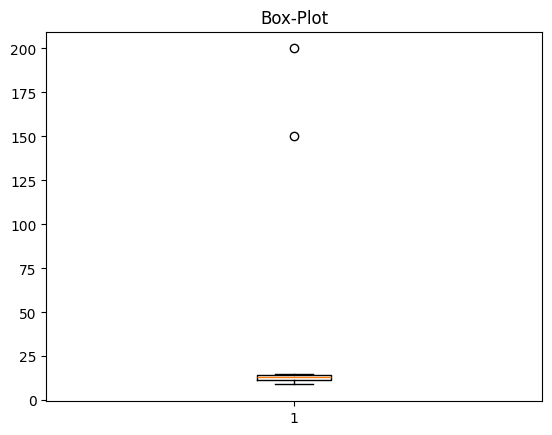

In [ ]:
plt.boxplot(df['Value'])
plt.title('Box-Plot')
plt.show()

In [ ]:
#calculate IQR
Q1=df['Value'].quantile(0.25)
Q3=df['Value'].quantile(0.75)
IQR=Q3-Q1

lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
print(lower_bound)
print(upper_bound)

7.0
19.0


In [ ]:
#Detect the outliers
outliers=df[(df['Value']<lower_bound) | (df['Value'] > upper_bound )]
print("outliers",outliers)

outliers    Value
5    150
9    200


In [ ]:
#remove outliers
df_clean = df[(df['Value']>= lower_bound) & (df['Value']<= upper_bound)]
print("cleaned data",df_clean)

cleaned data     Value
0      10
1      12
2      13
3      12
4      14
6      11
7      13
8       9
10     15
